**IMPORTING LIBRARIES**

In [184]:
import pandas as pd 
import numpy as np 
import seaborn as sns
import plotly.express as px
import matplotlib.pyplot as plt

**LOADING THE DATASET**

In [185]:
df = pd.read_csv("crop_yield_dataset.csv")

df.head()

,area,year,average_rain_fall_mm_per_year,pesticides_tonnes,avg_temp,item,value_hg_ha
0,Albania,1990,1485.0,121.0,16.37,Maize,36613
1,Albania,1990,1485.0,121.0,16.37,Potatoes,66667
2,Albania,1990,1485.0,121.0,16.37,"Rice, paddy",23333
3,Albania,1990,1485.0,121.0,16.37,Sorghum,12500
4,Albania,1990,1485.0,121.0,16.37,Soybeans,7000


**DATASET INSPECTION**

In [186]:
# Data shape
print("Dataset Shape:", df.shape)

# Columns in Dataset
print("Columns in Dataset:", df.columns)

Dataset Shape: (25932, 7)
Columns in Dataset: Index(['area', 'year', 'average_rain_fall_mm_per_year', 'pesticides_tonnes',
       'avg_temp', 'item', 'value_hg_ha'],
      dtype='str')


In [187]:
# Dataset Info
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 25932 entries, 0 to 25931
Data columns (total 7 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   area                           25932 non-null  str    
 1   year                           25932 non-null  int64  
 2   average_rain_fall_mm_per_year  25932 non-null  float64
 3   pesticides_tonnes              25932 non-null  float64
 4   avg_temp                       25932 non-null  float64
 5   item                           25932 non-null  str    
 6   value_hg_ha                    25932 non-null  int64  
dtypes: float64(3), int64(2), str(2)
memory usage: 1.4 MB


In [188]:
#checking for null values
df.isnull().sum()

area                             0
year                             0
average_rain_fall_mm_per_year    0
pesticides_tonnes                0
avg_temp                         0
item                             0
value_hg_ha                      0
dtype: int64

**DATA CLEANING**

In [189]:
#renaming columns
df = df.rename(columns={
    "average_rain_fall_mm_per_year": "avg_rainfall_per_year",
    "value_hg_ha": "crop_value"
})
df.to_csv("cleaned_crop_yield_dataset.csv", index=False)

**EDA - DATASET ANALYSIS**

In [190]:
df = pd.read_csv("cleaned_crop_yield_dataset.csv")

In [191]:
#distribuiton of area
df["area"].value_counts()

area
India         3384
Brazil        1854
Mexico        1280
Australia      966
Pakistan       966
              ... 
Latvia          42
Belgium         39
Bahrain         29
Sudan           28
Montenegro      24
Name: count, Length: 101, dtype: int64

In [192]:
#distribution of items
df["item"].value_counts()

item
Potatoes                3956
Maize                   3824
Wheat                   3539
Rice, paddy             3091
Soybeans                2940
Sorghum                 2770
Sweet potatoes          2593
Cassava                 1889
Yams                     774
Plantains and others     556
Name: count, dtype: int64

In [193]:
#distribution of year 

In [194]:
df["year"].value_counts()

year
2012    1166
2013    1165
2010    1151
2008    1150
2007    1148
2011    1145
2004    1141
2006    1135
1993    1130
1995    1129
2000    1129
2001    1128
2002    1127
2005    1127
1992    1126
1999    1123
2009    1123
1996    1121
1997    1115
1998    1115
1994    1112
1990    1063
1991    1063
Name: count, dtype: int64

In [195]:
#distribution of area by values : crop values
df.groupby("area")["crop_value"].sum().sort_values(ascending=False).head(15).map('{:,.0f}'.format)

area
India             274,219,558
Brazil            136,340,329
Mexico            113,698,872
Australia         109,111,062
Japan             100,924,145
Indonesia          68,067,328
Turkey             52,263,950
Pakistan           49,264,956
Spain              46,773,540
United Kingdom     44,335,992
Germany            38,780,463
Egypt              36,828,848
Canada             34,706,922
Argentina          32,864,032
Italy              32,280,700
Name: crop_value, dtype: str

In [196]:
# avarage values by area
df.groupby("area")["crop_value"].mean().sort_values(ascending=False).head(15).map('{:,.2f}'.format)

area
United Kingdom    240,956.48
Belgium           216,468.46
Denmark           214,033.02
Netherlands       204,151.20
Ireland           197,913.70
New Zealand       191,931.83
Sweden            187,405.50
Bahrain           153,237.55
Norway            146,115.33
Switzerland       144,960.28
Germany           143,631.34
Finland           135,014.52
Japan             128,729.78
Mauritius         125,586.26
Jamaica           122,347.87
Name: crop_value, dtype: str

In [197]:
#distribution of items by values
df.groupby("item")["crop_value"].sum().sort_values(ascending=False).map('{:,.0f}'.format)

item
Potatoes                785,921,609
Sweet potatoes          310,269,345
Cassava                 275,132,269
Maize                   142,020,761
Rice, paddy             127,646,024
Wheat                   106,614,786
Yams                     86,769,760
Plantains and others     58,958,974
Sorghum                  52,906,376
Soybeans                 49,957,039
Name: crop_value, dtype: str

In [198]:
#distribution of items by avg values
df.groupby("item")["crop_value"].mean().sort_values(ascending=False).map('{:,.2f}'.format)

item
Potatoes                198,665.73
Cassava                 145,649.69
Sweet potatoes          119,656.52
Yams                    112,105.63
Plantains and others    106,041.32
Rice, paddy              41,296.03
Maize                    37,139.32
Wheat                    30,125.68
Sorghum                  19,099.77
Soybeans                 16,992.19
Name: crop_value, dtype: str

In [199]:
#distributio of years by crop values 
df.groupby("year")["crop_value"].sum().sort_values(ascending=False).map('{:,.0f}'.format)

year
2013    105,271,377
2012    103,330,379
2011    101,652,500
2010     99,454,324
2008     96,860,877
2009     95,743,109
2007     94,671,281
2004     91,894,642
2006     91,089,050
2005     90,019,869
2002     87,390,673
2001     86,278,048
2000     84,897,839
1999     82,536,159
1998     79,667,393
1997     79,299,386
1995     78,423,369
1996     78,356,024
1993     76,352,388
1994     76,029,174
1992     75,368,149
1990     70,925,645
1991     70,685,288
Name: crop_value, dtype: str

In [200]:
#distributio of years by avg crop values 
df.groupby("year")["crop_value"].mean().sort_values(ascending=False).map('{:,.2f}'.format)

year
2013    90,361.70
2011    88,779.48
2012    88,619.54
2010    86,406.88
2009    85,256.55
2008    84,226.85
2007    82,466.27
2004    80,538.69
2006    80,254.67
2005    79,875.66
2002    77,542.74
2001    76,487.63
2000    75,197.38
1999    73,496.13
1998    71,450.58
1997    71,120.53
1996    69,898.33
1995    69,462.68
1994    68,371.56
1993    67,568.48
1992    66,934.41
1990    66,722.15
1991    66,496.04
Name: crop_value, dtype: str

In [201]:
# distribution of area by rain fall
df.groupby("area")["avg_rainfall_per_year"].sum().sort_values(ascending=False).head(15)

area
India                 3664872.0
Brazil                3264894.0
Indonesia             2204832.0
Ecuador               1412154.0
Colombia              1341360.0
Japan                 1307712.0
Mexico                 970240.0
Dominican Republic     518880.0
Australia              515844.0
Papua New Guinea       505862.0
Pakistan               477204.0
Nicaragua              417240.0
Guatemala              407184.0
Honduras               403104.0
Bangladesh             391902.0
Name: avg_rainfall_per_year, dtype: float64

In [202]:
# distribution of area by avg rain fall
df.groupby("area")["avg_rainfall_per_year"].mean().sort_values(ascending=False).head(15)

area
Colombia            3240.0
Papua New Guinea    3142.0
Malaysia            2875.0
Indonesia           2702.0
Bangladesh          2666.0
Guyana              2387.0
Suriname            2331.0
Nicaragua           2280.0
Ecuador             2274.0
Jamaica             2051.0
Mauritius           2041.0
Guatemala           1996.0
Honduras            1976.0
El Salvador         1784.0
Brazil              1761.0
Name: avg_rainfall_per_year, dtype: float64

In [203]:
# distribution of area by pesticides
df.groupby("area")["pesticides_tonnes"].sum().sort_values(ascending=False).head(15).map('{:,.0f}'.format)

area
Brazil          350,458,110
India           163,714,023
Mexico           55,730,915
Japan            55,127,436
Australia        31,989,206
Italy            25,816,638
Argentina        24,998,041
Canada           23,792,433
Colombia         21,932,769
Turkey           20,818,242
Spain            18,583,089
France           11,762,903
South Africa     11,373,239
Germany           9,508,614
Pakistan          8,336,783
Name: pesticides_tonnes, dtype: str

In [204]:
# distribution of area by avg pesticides
df.groupby("area")["pesticides_tonnes"].mean().sort_values(ascending=False).head(15).map('{:,.2f}'.format)

area
Brazil       189,028.11
France        85,238.43
Italy         80,175.90
Japan         70,315.61
Argentina     67,929.46
Colombia      52,977.70
India         48,378.85
Ukraine       46,535.49
Mexico        43,539.78
Malaysia      43,334.31
Canada        43,102.23
Thailand      39,464.17
Spain         38,474.30
Germany       35,217.09
Turkey        33,309.19
Name: pesticides_tonnes, dtype: str

In [205]:
# pesticides vs items: sum
df.groupby("item")["pesticides_tonnes"].sum().sort_values(ascending=False).head(15).map('{:,.0f}'.format)

item
Potatoes                119,595,406
Wheat                   118,857,483
Maize                   117,787,531
Soybeans                114,136,750
Rice, paddy             107,919,142
Sweet potatoes           96,764,472
Sorghum                  96,246,483
Cassava                  76,214,223
Yams                     50,050,557
Plantains and others      4,409,641
Name: pesticides_tonnes, dtype: str

In [206]:
#pesticides vs items: mean
df.groupby("item")["pesticides_tonnes"].mean().sort_values(ascending=False).head(15).map('{:,.2f}'.format)

item
Yams                    64,664.80
Cassava                 40,346.33
Soybeans                38,822.02
Sweet potatoes          37,317.57
Rice, paddy             34,913.99
Sorghum                 34,746.02
Wheat                   33,585.05
Maize                   30,802.18
Potatoes                30,231.40
Plantains and others     7,931.01
Name: pesticides_tonnes, dtype: str

**VISUALIZATION**

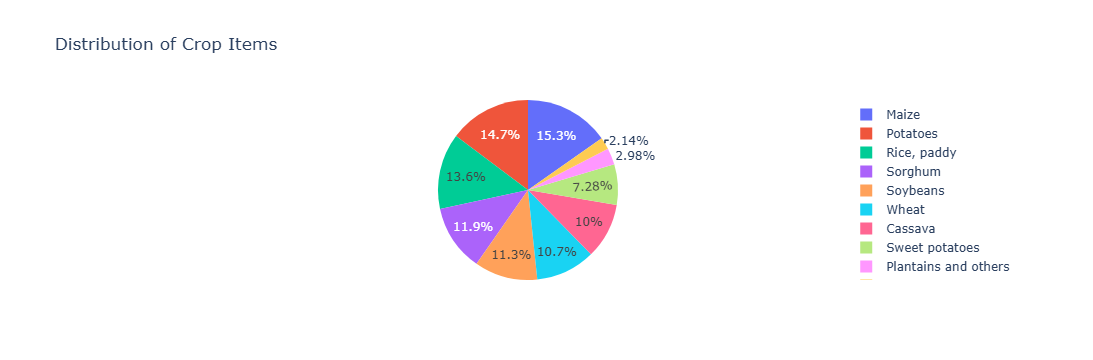

In [207]:
#distribution of item : pie chart
fig = px.pie(
    names=df["item"].unique(),
    values=df["item"].value_counts(),
    title="Distribution of Crop Items"
)

fig.show()

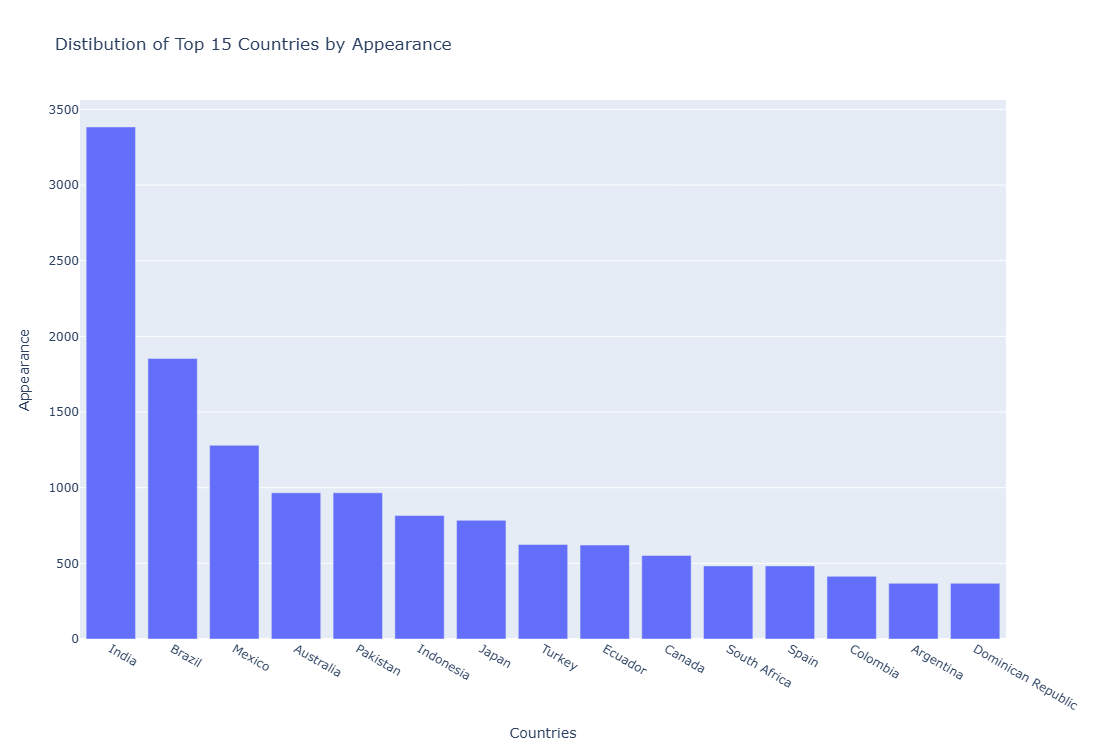

In [208]:
#distribution of countries/area : bar chart
area_count = df["area"].value_counts().head(15)
fig1 = px.bar(
    x = area_count.index,
    y = area_count.values,
    orientation="v",
    title = "Distibution of Top 15 Countries by Appearance"
)
fig1.update_layout(
    width=1000,
    height=750,
    xaxis_title="Countries",
    yaxis_title= "Appearance"
)

fig1.show()

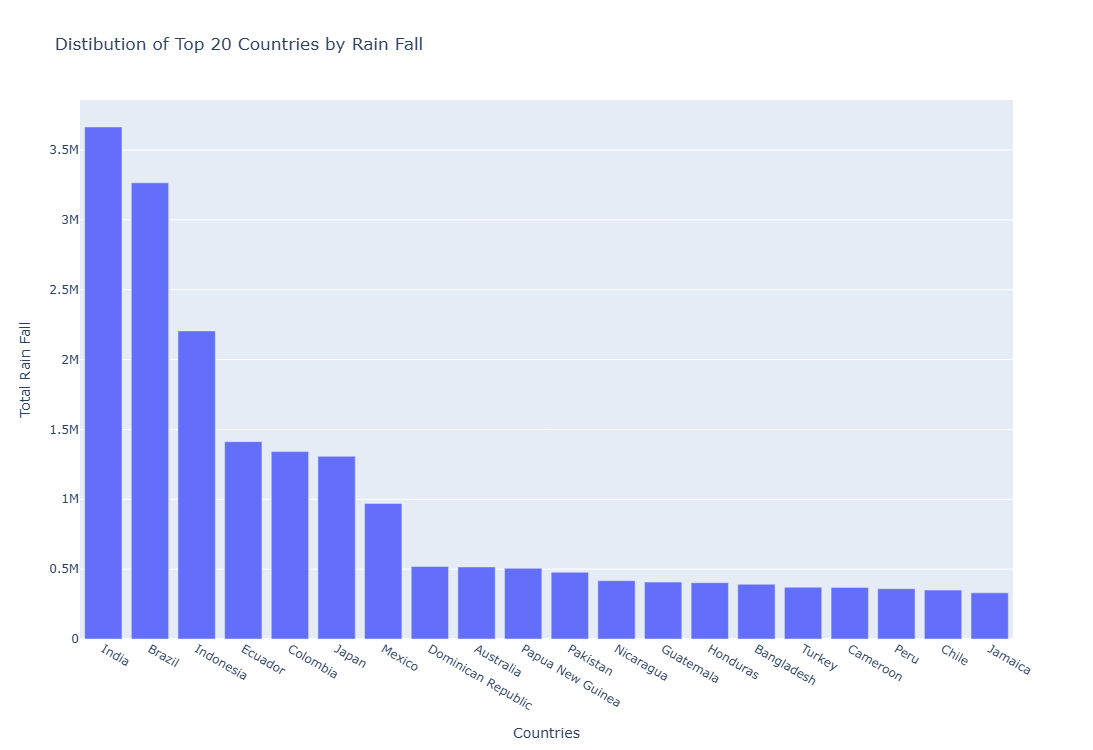

In [209]:
#Dustribution of area by rain fall
area_rain = df.groupby("area")["avg_rainfall_per_year"].sum().sort_values(ascending=False).head(20)

fig2 = px.bar(
    x = area_rain.index,
    y = area_rain.values,
    orientation="v",
    title = "Distibution of Top 20 Countries by Rain Fall"
)
fig2.update_layout(
    width=1000,
    height=750,
    xaxis_title="Countries",
    yaxis_title= "Total Rain Fall"
)

fig2.show()

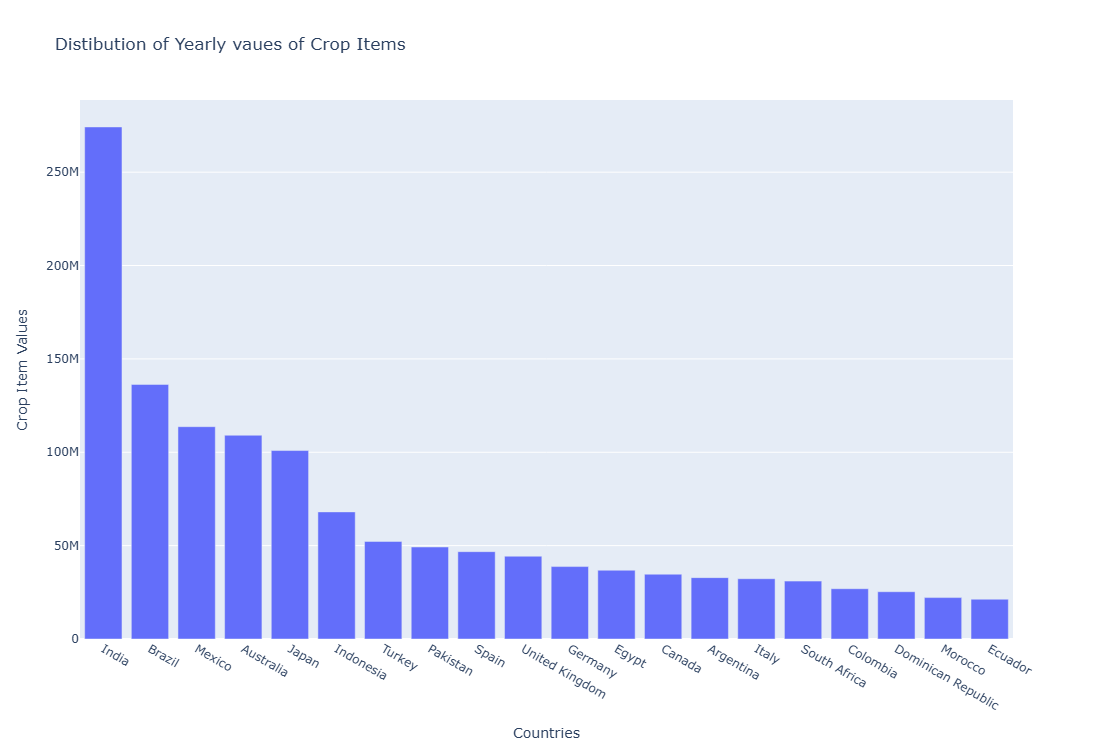

In [210]:
#distribution of countries by crop values
area_values = df.groupby("area")["crop_value"].sum().sort_values(ascending=False).head(20)

fig3 = px.bar(
    x = area_values.index,
    y = area_values.values,
    title = "Distibution of Yearly vaues of Crop Items"
)
fig3.update_layout(
    width=1000,
    height=750,
    xaxis_title="Countries",
    yaxis_title= "Crop Item Values"
)

fig3.show()

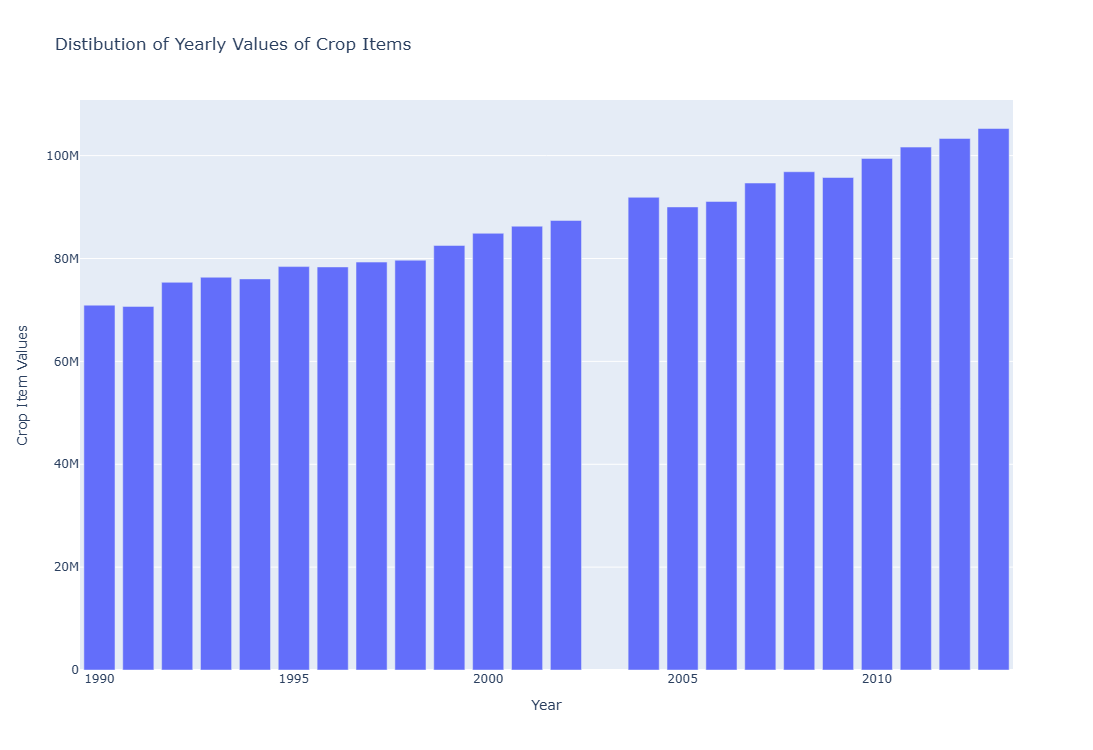

In [211]:
#distribution of crop items over time
year_dist = df.groupby("year")["crop_value"].sum()

fig4 = px.bar(
    x = year_dist.index,
    y = year_dist.values,
    orientation="v",
    title = "Distibution of Yearly Values of Crop Items"
)
fig4.update_layout(
    width=1000,
    height=750,
    xaxis_title="Year",
    yaxis_title= "Crop Item Values"
)

fig4.show()

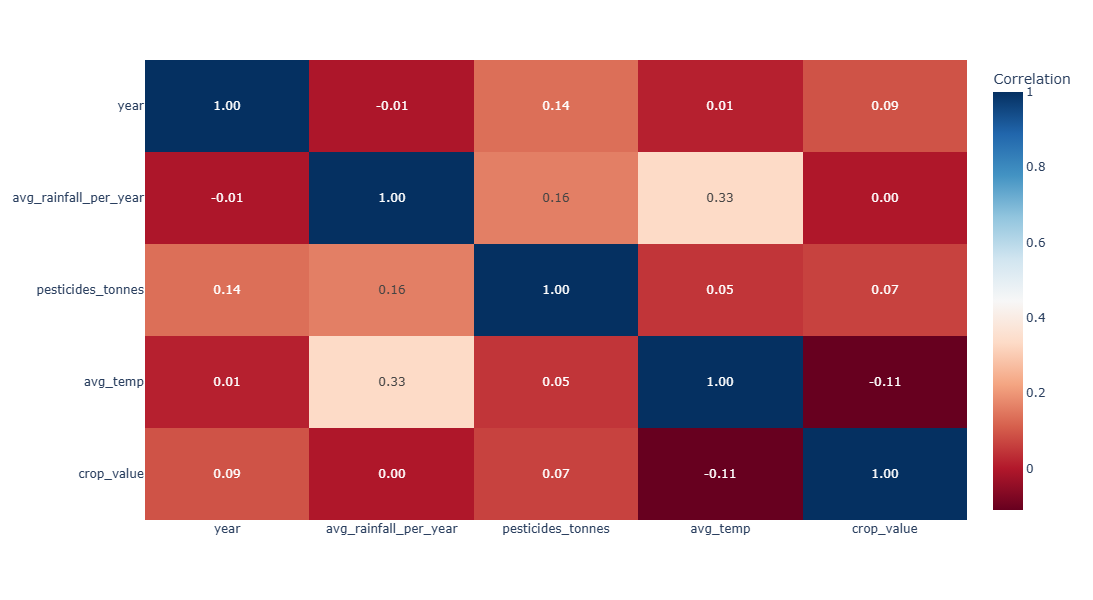

In [215]:
correlation = df[["year", "avg_rainfall_per_year", "pesticides_tonnes", "avg_temp", "crop_value"]].corr()
fig5 = px.imshow(
    correlation,
    text_auto=".2f",
    aspect="auto",
    labels=dict(color="Correlation"),
    color_continuous_scale="RdBu",   
    width=800,                           
    height=600
)

fig5.show()